This notebook works through the modeling choices for Milestone 3: what to predict, how to
validate it without leaking the future, which models to compare against which baselines, and
what the results say about the research questions. It works from the analysis dataset described
on the Pipeline and Quality Checks and Exploration pages: one row per drug (ingredient + route)
per year on the market, 2020 to 2025, with every feature measured as of the end of the year
before.

To reproduce it, run the pipeline in the repository README, then re-run this notebook from the
`notebooks/` folder. All randomness (forests, bootstrap resampling, tie-breaking) is seeded with
`SEED` below.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

REPO_ROOT = Path.cwd().parent
assert (REPO_ROOT / "pyproject.toml").exists(), "run this notebook from the notebooks/ folder"
INTERIM_DATA_DIR = REPO_ROOT / "data" / "interim"
PROCESSED_DATA_DIR = REPO_ROOT / "data" / "processed"

sys.path.insert(0, str(REPO_ROOT / "src" / "panel"))
import add_features as feature_building  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", None)

SEED = 5502
rng = np.random.default_rng(SEED)

features = pd.read_parquet(PROCESSED_DATA_DIR / "unit_year_features.parquet")
units = pd.read_parquet(INTERIM_DATA_DIR / "units.parquet")
application_units = pd.read_parquet(INTERIM_DATA_DIR / "application_units.parquet")

In [2]:
SURFACE, TEXT_PRIMARY, TEXT_SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.size": 10,
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlecolor": TEXT_PRIMARY,
        "axes.titlepad": 12,
        "axes.labelcolor": TEXT_SECONDARY,
        "xtick.color": TEXT_SECONDARY,
        "ytick.color": TEXT_SECONDARY,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.edgecolor": BASELINE,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "legend.frameon": False,
        "lines.linewidth": 2,
    }
)


def wilson_interval(successes, trials, z=1.96):
    """95% confidence interval for a proportion; stays sensible when counts are small."""
    successes, trials = np.asarray(successes, float), np.asarray(trials, float)
    rate = successes / trials
    denominator = 1 + z**2 / trials
    center = (rate + z**2 / (2 * trials)) / denominator
    half_width = z * np.sqrt(rate * (1 - rate) / trials + z**2 / (4 * trials**2)) / denominator
    return np.clip(center - half_width, 0, None), center + half_width


def dot_plot(ax, table, value, low, high, colors, reference=None, reference_label=None):
    """Horizontal dots with interval bars, one row per index entry of table (top to bottom)."""
    y = np.arange(len(table))[::-1]
    for position, (_, row), color in zip(y, table.iterrows(), colors):
        ax.plot([row[low], row[high]], [position, position], color=color, linewidth=1.5)
        ax.plot(row[value], position, "o", color=color, markersize=7)
    if reference is not None:
        ax.axvline(reference, color=MUTED, linewidth=1)
        if reference_label:
            ax.text(reference, len(table) - 0.45, f" {reference_label}", color=TEXT_SECONDARY,
                    fontsize=8.5, va="bottom")
    ax.set_yticks(y, table.index)
    ax.set_ylim(-0.6, len(table) - 0.1)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)

## 1. Modeling plan

| Research question | What is modeled | Task type |
|---|---|---|
| RQ1: How predictable is shortage onset? | Each drug's risk of a new shortage in year *t*, from what was known at the end of *t*−1; drugs ranked by that risk | Binary classification, used as a ranking (risk scores) |
| RQ2: What distinguishes drugs that go into shortage? | Which features the models rely on: logistic-regression coefficients, and how performance changes as feature groups are added | Interpretation of the RQ1 models |
| RQ3: Do manufacturers exit before a shortage? | Whether exit features add predictive value beyond the other features (a predictive test, not the event study planned for this question) | Feature-group ablation |
| RQ4: Does predictability hold across drug types? | The same predictions, scored separately for injectable and oral drugs, and models trained on one group and tested on the other | Subgroup evaluation |

Output: 
The practical output is a watchlist: a hospital
pharmacy or purchasing group can't act on 2,000 drugs, but it can watch the 50 riskiest. With
onsets in about 1.8% of drug-years, a yes/no prediction at any usable threshold would be "no"
almost everywhere, so models are judged on how well they order drugs, and separately on whether
their probabilities are believable.

Methods:
The data is small in the way that matters: about 11,500 at-risk drug-years but only 161 onsets, with around 13 features, most of them skewed counts, plus one
categorical (route). That favors:

- Regularized logistic regression. Few parameters, stable with 100 or so positive examples,
  and its coefficients answer RQ2 directly. Counts are log-transformed because the Exploration
  page found them heavily skewed.
- Random forest and gradient-boosted trees. These find thresholds and interactions on
  their own (for example, age mattering more for injectables) without hand-built terms, and are
  indifferent to skew. With so few positives they need strong regularization (large leaves,
  shallow trees), which is what the tuning grids search over.

**Assumptions and failure modes specific to this data.**

- The same drug appears in up to six years, so rows are not independent. Confidence intervals
  resample whole drugs, not rows.
- The base rate collapses after 2023 (11 onsets in 2024, 3 in 2025). A model trained on
  2020–2023 will overpredict after that since the incidences are so much higher even if it ranks well, so ranking and calibration are
  scored separately, and 2024–2025 is treated as a check after the collapse, not a test set.
- Shortage history starts in late 2019, so `had_prior_shortage` is rare in 2020 and becomes
  more common every year as the archive accumulates history (the table below). A feature whose meaning drifts over time is a real risk for
  any model trained on early years and tested on later ones.
- "Onset" means FDA listed the drug, and short shortages between archive captures are missing.
  A model learns to predict FDA listings of lasting shortages, not supply failure itself.

## 2. Data preparation for modeling

### Rows

A row is a drug-year **at risk**: a drug with a package on the market at the end of *t*−1 that was
not already in shortage on January 1 of *t*. Drugs already in shortage are excluded, because
predicting that a running shortage continues is easy and useless (it is what made a persistence
rule score a ROC-AUC of 0.97 in prior public work, as discussed on the Background page).

### Features used, excluded, and constructed

| Group | Features | Preparation |
|---|---|---|
| Product | route group; years since first approval; **approved before 1982** (constructed) | Route: rare groups (inhalation, nasal, other, otic, rectal, vaginal) pooled as "other", one-hot with oral as the reference. Age: standardized. |
| Market size | packages on the market; active approvals; companies ever approved | log(1 + count), then standardized |
| History and quality | had a prior shortage; recalls in the prior year | flag as-is; log(1 + count), standardized |
| Exits (RQ3) | package exits, approval exits, and FDA discontinuation notices in the prior year; **share of packages that exited** (constructed) | counts: log(1 + count), standardized; share: standardized |

Tree models get the same columns untransformed (they are unaffected by monotone transforms),
with route one-hot encoded.

Constructed features: The Orange Book records approvals before 1982 only as "approved prior to
Jan 1, 1982", so for 81 of the 161 onsets drug age is a lower bound; the flag lets a model give
those drugs their own effect. The exit share (exits ÷ (packages on the market + exits)) expresses
exits relative to market size, since the Exploration page found raw exit counts largely track how
many packages a drug has.

Intentionally excluded:

| Feature | Why |
|---|---|
| labelers; generic approvals | Rank-correlated 0.8–0.9 with packages and approvals (Exploration page): redundant with only 161 onsets |
| Class I recalls | Nonzero in about 1% of drug-years; kept only inside total recalls |
| calendar year | Test years always lie beyond the training years, so a year effect can only extrapolate a trend; it would also leak the post-2023 collapse into the evaluation if fit on it |
| FDA's stated shortage reason; days since posting; anything from the shortage record itself | Known only once a shortage exists: target leakage (the banned list from Milestone 2) |
| in shortage on January 1 | Defines which rows are at risk, so it is constant within the modeling rows |
| Medicare Part B/D spending | Not reliably linked to drugs yet (Milestone 2) |

Leakage guards: Every feature is measured as of December 31 of *t*−1
(enforced in `src/panel/add_features.py`). Transformations that learn from data (the scalers, the
route-rate baseline, every model) are fit inside a scikit-learn pipeline on the training years
only. Route pooling and the excluded list were fixed from group sizes and correlations, not from
outcomes in test years.

In [3]:
# The Orange Book gives no date for approvals before 1982, so those drugs' ages are lower bounds.
first_approval = (
    feature_building.load_unit_approvals(application_units).groupby("unit_id")["approved"].min()
)
undated_units = first_approval.index[first_approval == feature_building.PRE_1982_APPROVAL]

# Route groups with too few onsets to estimate on their own (Exploration page) are pooled.
ROUTES_KEPT = ["injectable", "oral", "ophthalmic", "topical"]

panel = features.assign(
    approved_before_1982=features["unit_id"].isin(undated_units).astype(int),
    had_prior_shortage=features["had_prior_shortage"].astype(int),
    route=features["route_group"].where(features["route_group"].isin(ROUTES_KEPT), "other"),
    package_exit_share=features["package_exits_prior_year"]
    / (features["active_packages"] + features["package_exits_prior_year"]),
).merge(units[["unit_id", "ingredient"]], on="unit_id")
data = panel[panel["at_risk"]].reset_index(drop=True)

FEATURE_GROUPS = {
    "product": ["route", "years_since_first_approval", "approved_before_1982"],
    "market size": ["active_packages", "active_applications", "cumulative_applicants"],
    "history and quality": ["had_prior_shortage", "recalls_prior_year"],
    "exits": [
        "package_exits_prior_year",
        "application_exits_prior_year",
        "discontinuation_notices_prior_year",
        "package_exit_share",
    ],
}
ALL_FEATURES = [column for group in FEATURE_GROUPS.values() for column in group]
LOG_COUNTS = [
    "active_packages",
    "active_applications",
    "cumulative_applicants",
    "recalls_prior_year",
    "package_exits_prior_year",
    "application_exits_prior_year",
    "discontinuation_notices_prior_year",
]
FLAGS = ["approved_before_1982", "had_prior_shortage"]
SCALED = ["years_since_first_approval", "package_exit_share"]

data.groupby("year").agg(
    at_risk_drugs=("onset", "size"),
    onsets=("onset", "sum"),
    onset_rate=("onset", "mean"),
    share_with_prior_shortage=("had_prior_shortage", "mean"),
).style.format({"onset_rate": "{:.2%}", "share_with_prior_shortage": "{:.1%}"})

,at_risk_drugs,onsets,onset_rate,share_with_prior_shortage
year,,,,
2020,1858,44,2.37%,2.1%
2021,1878,35,1.86%,3.5%
2022,1911,35,1.83%,5.2%
2023,1911,33,1.73%,5.5%
2024,1950,11,0.56%,7.1%
2025,1992,3,0.15%,8.6%


The last column shows the drift named above: the share of at-risk drugs with a recorded earlier
shortage quadruples, from 2.1% in 2020 to 8.6% in 2025, because the archive only starts in late
2019, not because drugs became more shortage-prone. A model trained on 2020 sees this feature
for very few drugs.

## 3. Validation design

**Rolling-origin (expanding-window) validation, never random splits.** Random k-fold would train
on 2023 to predict 2021, letting a model learn the later base rate and the later meaning of
shortage history. Instead, each test year *T* in 2021, 2022 and 2023 gets a model trained on all
at-risk rows from years before *T*. Their predictions are pooled into one out-of-sample set of
5,700 drug-years and 103 onsets, which is what every comparison below is scored on. Within each fold, hyperparameters are chosen by the same
rolling scheme applied to the training years only: for test year 2023, candidates are scored on
2021 (trained on 2020) and 2022 (trained on 2020–2021). For test year 2022 the only validation
year is 2021. For test year 2021 there is a single training year, so each model uses a default
fixed in advance, which is the honest cost of a short history.

2024–2025 are scored separately, rolling forward the same way, as a check of what happens after
the collapse in new shortages. With only 14 onsets, the data is too meager to support model selection.

Evaluation Metrics:

| Metric | Why |
|---|---|
| PR-AUC (average precision), compared with the base rate | Primary. Summarizes precision across every watchlist length. With 1.8% positives, ROC-AUC can look respectable while the top of the list is mostly false alarms; PR-AUC can't. A model with no skill scores the base rate. |
| ROC-AUC | Probability that a random onset is ranked above a random non-onset. Comparable across years with different base rates, and with published work. |
| Watchlist hits (onsets among the top 50 drugs each year) | The operational number: of 50 drugs a pharmacy might monitor, how many go short. 50 is about 2.6% of at-risk drugs. |
| Calibration (reliability plot, Brier skill score) | The proposal promised probabilities, not just ranks; they only help planning if a 5% risk means 5%. |

Accuracy and F1 at a 0.5 threshold are not reported: every model predicts "no" for every row at
that threshold, and accuracy would be 98% for a model that does nothing.

Intervals are 95% bootstrap intervals that resample whole drugs (1,000 resamples), and model
differences are computed on the same resamples, so they are paired.

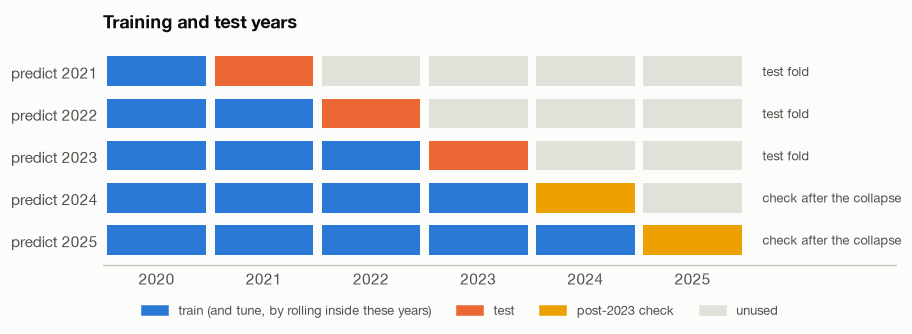

In [4]:
#| label: fig-validation-design
#| fig-cap: "Rolling-origin validation: each test year is predicted by a model trained on all earlier years"
ALL_YEARS = list(range(2020, 2026))
OUTER_TEST_YEARS = [2021, 2022, 2023]
LATE_YEARS = [2024, 2025]

fig, ax = plt.subplots(figsize=(8.5, 3.2))
rows = [(year, "test fold") for year in OUTER_TEST_YEARS] + [
    (year, "check after the collapse") for year in LATE_YEARS
]
for position, (test_year, kind) in enumerate(rows):
    y = len(rows) - 1 - position
    for year in ALL_YEARS:
        if year < test_year:
            color = BLUE
        elif year == test_year:
            color = ORANGE if kind == "test fold" else YELLOW
        else:
            color = GRID
        ax.barh(y, 0.92, left=year - 0.46, height=0.7, color=color)
    ax.text(2025.65, y, kind, va="center", fontsize=8.5, color=TEXT_SECONDARY)
ax.set_yticks(range(len(rows)), [f"predict {year}" for year, _ in rows][::-1])
ax.set_xticks(ALL_YEARS, [str(year) for year in ALL_YEARS])
ax.set_xlim(2019.5, 2026.9)
ax.grid(False)
ax.legend(
    handles=[
        Patch(color=BLUE, label="train (and tune, by rolling inside these years)"),
        Patch(color=ORANGE, label="test"),
        Patch(color=YELLOW, label="post-2023 check"),
        Patch(color=GRID, label="unused"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.45, -0.12),
    ncol=4,
    fontsize=8.5,
    labelcolor=TEXT_SECONDARY,
)
ax.set_title("Training and test years")
fig.tight_layout()
plt.show()

## 4. Models

Two baselines make the candidates' numbers interpretable, and three candidates are compared under
the identical protocol:

| Model | Role | Hyperparameters searched (default for the first fold) |
|---|---|---|
| **Prior shortage** | Baseline promised on the Research Questions page: flag drugs that had an earlier shortage | none |
| **Route rate** | Baseline: each drug gets its route group's onset rate in the training years. Captures the single biggest difference found in exploration. | none |
| **Logistic regression** (L2) | Candidate | inverse regularization `C` ∈ {0.01, 0.03, 0.1, 0.3, 1, 3} (1) |
| **Random forest** | Candidate | min leaf size ∈ {20, 50, 100}, features per split ∈ {√p, half} (50, √p); 300 trees |
| **Gradient-boosted trees** | Candidate | learning rate ∈ {0.03, 0.1}, max depth ∈ {2, 3}, min leaf size ∈ {40, 100} (0.1, 3, 40); 200 rounds, L2 = 1 |

The grids are small on purpose. Each validation year has about 35 onsets, so a large search would
mostly select noise. Grid points are compared by mean PR-AUC over the validation years.
Class weights are left off: they don't change a ranking much, and they would distort the
probabilities that calibration checks.

In [5]:
def logistic_regression(columns, C=1.0):
    def present(names):
        return [name for name in names if name in columns]

    transformers = [
        (
            "log_counts",
            make_pipeline(
                FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()
            ),
            present(LOG_COUNTS),
        ),
        ("scaled", StandardScaler(), present(SCALED)),
        ("flags", "passthrough", present(FLAGS)),
    ]
    if "route" in columns:
        transformers.append(("route", OneHotEncoder(drop=["oral"]), ["route"]))
    return make_pipeline(
        ColumnTransformer([step for step in transformers if step[2]]),
        LogisticRegression(C=C, max_iter=5000),
    )


def encode_route(columns):
    if "route" not in columns:
        return "passthrough"
    return ColumnTransformer([("route", OneHotEncoder(), ["route"])], remainder="passthrough")


def random_forest(columns, min_samples_leaf=50, max_features="sqrt"):
    return make_pipeline(
        encode_route(columns),
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            n_jobs=-1,
            random_state=SEED,
        ),
    )


def gradient_boosting(columns, learning_rate=0.1, max_depth=3, min_samples_leaf=40):
    return make_pipeline(
        encode_route(columns),
        HistGradientBoostingClassifier(
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            max_iter=200,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=SEED,
        ),
    )


class PriorShortage:
    """Score 1 for drugs with an earlier shortage, 0 otherwise."""

    def __init__(self, columns):
        pass

    def fit(self, X, y):
        return self

    def predict_proba(self, X):
        flagged = X["had_prior_shortage"].to_numpy(float)
        return np.column_stack([1 - flagged, flagged])


class RouteRate:
    """Score each drug with its route group's onset rate in the training years."""

    def __init__(self, columns):
        pass

    def fit(self, X, y):
        self.rates_ = y.groupby(X["route"].to_numpy()).mean()
        return self

    def predict_proba(self, X):
        rate = X["route"].map(self.rates_).to_numpy(float)
        return np.column_stack([1 - rate, rate])


MODELS = {
    "prior shortage (baseline)": {"build": PriorShortage, "grid": [{}], "default": {}},
    "route rate (baseline)": {"build": RouteRate, "grid": [{}], "default": {}},
    "logistic regression": {
        "build": logistic_regression,
        "grid": [{"C": C} for C in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]],
        "default": {"C": 1.0},
    },
    "random forest": {
        "build": random_forest,
        "grid": [
            {"min_samples_leaf": leaf, "max_features": features_per_split}
            for leaf in [20, 50, 100]
            for features_per_split in ["sqrt", 0.5]
        ],
        "default": {"min_samples_leaf": 50, "max_features": "sqrt"},
    },
    "gradient boosting": {
        "build": gradient_boosting,
        "grid": [
            {"learning_rate": rate, "max_depth": depth, "min_samples_leaf": leaf}
            for rate in [0.03, 0.1]
            for depth in [2, 3]
            for leaf in [40, 100]
        ],
        "default": {"learning_rate": 0.1, "max_depth": 3, "min_samples_leaf": 40},
    },
}
BASELINES = [name for name in MODELS if "baseline" in name]
CANDIDATES = [name for name in MODELS if name not in BASELINES]
MODEL_COLORS = {
    "prior shortage (baseline)": MUTED,
    "route rate (baseline)": MUTED,
    "logistic regression": BLUE,
    "random forest": AQUA,
    "gradient boosting": ORANGE,
}

In [6]:
def fit_and_predict(model, train, test, columns, params):
    fitted = model["build"](columns, **params).fit(train[columns], train["onset"])
    return fitted.predict_proba(test[columns])[:, 1]


def select_params(model, train, columns):
    """The grid point with the best mean PR-AUC over rolling validation years inside train."""
    validation_years = sorted(train["year"].unique())[1:]
    if len(model["grid"]) == 1 or not validation_years:
        return model["default"]

    def mean_validation_pr_auc(params):
        return np.mean([
            average_precision_score(
                train.loc[train["year"] == year, "onset"],
                fit_and_predict(
                    model, train[train["year"] < year], train[train["year"] == year], columns,
                    params,
                ),
            )
            for year in validation_years
        ])

    return max(model["grid"], key=mean_validation_pr_auc)


def rolling_predictions(model, columns=ALL_FEATURES, test_years=OUTER_TEST_YEARS,
                        train_rows=None, test_rows=None):
    """Out-of-sample scores for each test year, from a model tuned and trained on earlier years.

    train_rows and test_rows optionally restrict which drugs are trained and tested on.
    """
    train_rows = np.ones(len(data), bool) if train_rows is None else train_rows
    test_rows = np.ones(len(data), bool) if test_rows is None else test_rows
    predicted, chosen = [], {}
    for year in test_years:
        train = data[train_rows & (data["year"] < year)]
        test = data[test_rows & (data["year"] == year)]
        chosen[year] = select_params(model, train, columns)
        predicted.append(
            test[["unit_id", "year", "onset", "route"]].assign(
                score=fit_and_predict(model, train, test, columns, chosen[year])
            )
        )
    return pd.concat(predicted), chosen


predictions, chosen_params = {}, {}
for name, model in MODELS.items():
    predictions[name], chosen_params[name] = rolling_predictions(model)

scores = predictions["logistic regression"][["unit_id", "year", "onset", "route"]].copy()
for name in MODELS:
    scores[name] = predictions[name]["score"].to_numpy()
# Baselines give many drugs the same score; ties on a watchlist are broken at random.
scores["tiebreak"] = rng.random(len(scores))

pd.DataFrame(
    {
        name: {
            f"test {year}": ", ".join(f"{key}={value}" for key, value in params.items())
            or "(no hyperparameters)"
            for year, params in chosen_params[name].items()
        }
        for name in CANDIDATES
    }
).T.rename_axis("hyperparameters chosen")

,test 2021,test 2022,test 2023
hyperparameters chosen,,,
logistic regression,C=1.0,C=0.3,C=0.3
random forest,"min_samples_leaf=50, max_features=sqrt","min_samples_leaf=100, max_features=0.5","min_samples_leaf=100, max_features=0.5"
gradient boosting,"learning_rate=0.1, max_depth=3, min_samples_leaf=40","learning_rate=0.03, max_depth=2, min_samples_leaf=100","learning_rate=0.03, max_depth=2, min_samples_leaf=100"


**What tuning chose.** Once there was a year to validate on, every candidate moved toward more
regularization than its default: logistic regression from `C` = 1 to 0.3, the random forest to the
largest leaves searched, and gradient boosting to the slower learning rate and shallower trees.
That is what you would expect with about 35 onsets a year: the data supports only a simple model.

## 5. Comparison

In [7]:
WATCHLIST_SIZE = 50
RESAMPLES = 1000

rows_by_drug = list(scores.groupby("unit_id").indices.values())


def drug_resamples(rows_by_drug, resamples=RESAMPLES):
    """Row positions for each bootstrap resample of whole drugs."""
    return [
        np.concatenate([rows_by_drug[i] for i in rng.integers(0, len(rows_by_drug),
                                                              len(rows_by_drug))])
        for _ in range(resamples)
    ]


def watchlist_hits(frame, column, size=WATCHLIST_SIZE):
    """Onsets among each year's top-scored drugs, summed over years."""
    return sum(
        year_rows.sort_values([column, "tiebreak"], ascending=False).head(size)["onset"].sum()
        for _, year_rows in frame.groupby("year")
    )


def bootstrap_metrics(frame, columns, metric, resamples):
    """metric for each column on each resample: array (resamples, columns)."""
    onset = frame["onset"].to_numpy()
    values = frame[columns].to_numpy()
    return np.array([
        [metric(onset[rows], values[rows, column]) for column in range(len(columns))]
        for rows in resamples
    ])


resamples = drug_resamples(rows_by_drug)
model_names = list(MODELS)
pr_auc = np.array([average_precision_score(scores["onset"], scores[name]) for name in model_names])
roc_auc = np.array([roc_auc_score(scores["onset"], scores[name]) for name in model_names])
pr_auc_draws = bootstrap_metrics(scores, model_names, average_precision_score, resamples)
roc_auc_draws = bootstrap_metrics(scores, model_names, roc_auc_score, resamples)
BASE_RATE = scores["onset"].mean()
reference = model_names.index("logistic regression")

comparison = pd.DataFrame(
    {
        "PR-AUC": pr_auc,
        "PR-AUC low": np.percentile(pr_auc_draws, 2.5, axis=0),
        "PR-AUC high": np.percentile(pr_auc_draws, 97.5, axis=0),
        "ROC-AUC": roc_auc,
        "ROC-AUC low": np.percentile(roc_auc_draws, 2.5, axis=0),
        "ROC-AUC high": np.percentile(roc_auc_draws, 97.5, axis=0),
        "difference low": np.percentile(
            pr_auc_draws - pr_auc_draws[:, [reference]], 2.5, axis=0),
        "difference high": np.percentile(
            pr_auc_draws - pr_auc_draws[:, [reference]], 97.5, axis=0),
        "watchlist hits": [watchlist_hits(scores, name) for name in model_names],
    },
    index=model_names,
)

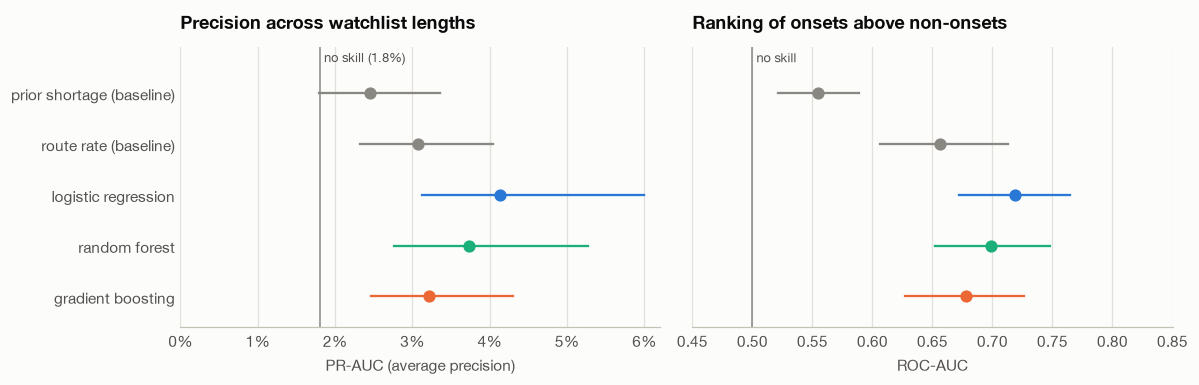

In [8]:
#| label: fig-model-comparison
#| fig-cap: "PR-AUC and ROC-AUC on the pooled 2021-2023 test years, with 95% intervals resampling drugs"
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
colors = [MODEL_COLORS[name] for name in comparison.index]
dot_plot(ax_pr, comparison, "PR-AUC", "PR-AUC low", "PR-AUC high", colors,
         reference=BASE_RATE, reference_label=f"no skill ({BASE_RATE:.1%})")
ax_pr.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_pr.set_xlim(0, None)
ax_pr.set_xlabel("PR-AUC (average precision)")
ax_pr.set_title("Precision across watchlist lengths")
dot_plot(ax_roc, comparison, "ROC-AUC", "ROC-AUC low", "ROC-AUC high", colors,
         reference=0.5, reference_label="no skill")
ax_roc.set_xlim(0.45, 0.85)
ax_roc.set_xlabel("ROC-AUC")
ax_roc.set_title("Ranking of onsets above non-onsets")
fig.tight_layout()
plt.show()

In [9]:
years_tested = scores["year"].nunique()
(
    comparison.assign(
        **{
            "PR-AUC (95% interval)": lambda table: [
                f"{value:.3f} ({low:.3f}–{high:.3f})"
                for value, low, high in zip(table["PR-AUC"], table["PR-AUC low"],
                                            table["PR-AUC high"])
            ],
            "× base rate": lambda table: (table["PR-AUC"] / BASE_RATE).round(1),
            "ROC-AUC (95% interval)": lambda table: [
                f"{value:.2f} ({low:.2f}–{high:.2f})"
                for value, low, high in zip(table["ROC-AUC"], table["ROC-AUC low"],
                                            table["ROC-AUC high"])
            ],
            "PR-AUC minus logistic regression (95% interval)": lambda table: [
                "—" if name == "logistic regression"
                else f"{value - table.loc['logistic regression', 'PR-AUC']:+.3f} "
                f"({low:+.3f} to {high:+.3f})"
                for name, value, low, high in zip(table.index, table["PR-AUC"],
                                                  table["difference low"],
                                                  table["difference high"])
            ],
            f"onsets in top {WATCHLIST_SIZE} (of {scores['onset'].sum()})": lambda table: table[
                "watchlist hits"],
            f"precision of top {WATCHLIST_SIZE}": lambda table: (
                table["watchlist hits"] / (WATCHLIST_SIZE * years_tested)).map("{:.1%}".format),
        }
    )
    .iloc[:, -6:]
    .rename_axis(f"pooled test years 2021–2023, base rate {BASE_RATE:.2%}")
)

,PR-AUC (95% interval),× base rate,ROC-AUC (95% interval),PR-AUC minus logistic regression (95% interval),onsets in top 50 (of 103),precision of top 50
"pooled test years 2021–2023, base rate 1.81%",,,,,,
prior shortage (baseline),0.024 (0.018–0.034),1.4,0.55 (0.52–0.59),-0.017 (-0.033 to -0.008),5,3.3%
route rate (baseline),0.031 (0.023–0.040),1.7,0.66 (0.61–0.71),-0.011 (-0.026 to -0.003),5,3.3%
logistic regression,0.041 (0.031–0.060),2.3,0.72 (0.67–0.76),—,6,4.0%
random forest,0.037 (0.028–0.053),2.1,0.70 (0.65–0.75),-0.004 (-0.016 to +0.006),10,6.7%
gradient boosting,0.032 (0.025–0.043),1.8,0.68 (0.63–0.73),-0.009 (-0.022 to -0.001),7,4.7%


**How to read the watchlist column.** A random list of 50 drugs a year would catch about
2.7 onsets over the three years (50 × 3 × the base rate).

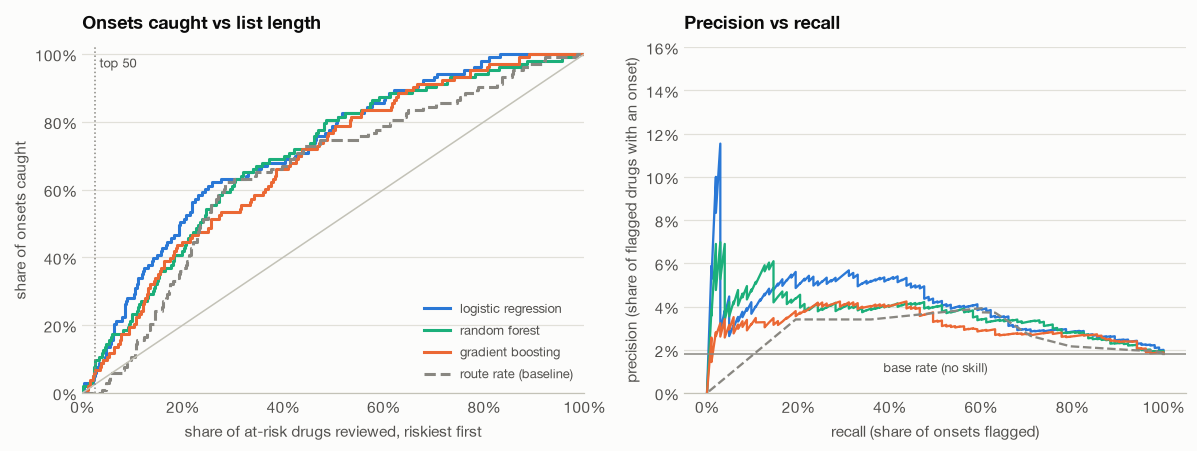

In [10]:
#| label: fig-gain-curves
#| fig-cap: "Share of onsets caught by reviewing the top of each year's ranking, and precision against recall"
fig, (ax_gain, ax_pr_curve) = plt.subplots(1, 2, figsize=(11, 4.2))
curve_models = ["logistic regression", "random forest", "gradient boosting",
                "route rate (baseline)"]
for name in curve_models:
    style = "--" if "baseline" in name else "-"
    ranked = scores.assign(
        share_reviewed=scores.groupby("year")[name].rank(ascending=False, pct=True,
                                                         method="first")
    )
    onset_positions = np.sort(ranked.loc[ranked["onset"] == 1, "share_reviewed"])
    ax_gain.step(
        np.concatenate([[0], onset_positions, [1]]),
        np.concatenate([[0], np.arange(1, len(onset_positions) + 1) / len(onset_positions), [1]]),
        where="post", color=MODEL_COLORS[name], linestyle=style, label=name,
    )
    precision, recall, _ = precision_recall_curve(scores["onset"], scores[name])
    # The last point is scikit-learn's (recall 0, precision 1) endpoint, not a real list.
    ax_pr_curve.plot(recall[:-1], precision[:-1], color=MODEL_COLORS[name], linestyle=style,
                     linewidth=1.5, label=name)
ax_gain.plot([0, 1], [0, 1], color=BASELINE, linewidth=1)
watchlist_share = WATCHLIST_SIZE / scores.groupby("year").size().mean()
ax_gain.axvline(watchlist_share, color=MUTED, linewidth=1, linestyle=":")
ax_gain.text(watchlist_share, 0.96, f" top {WATCHLIST_SIZE}", color=TEXT_SECONDARY, fontsize=8.5)
ax_gain.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_gain.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_gain.set_xlim(0, 1)
ax_gain.set_ylim(0, 1.02)
ax_gain.set_xlabel("share of at-risk drugs reviewed, riskiest first")
ax_gain.set_ylabel("share of onsets caught")
ax_gain.set_title("Onsets caught vs list length")
ax_gain.legend(loc="lower right", fontsize=8.5, labelcolor=TEXT_SECONDARY)

ax_pr_curve.axhline(BASE_RATE, color=MUTED, linewidth=1)
ax_pr_curve.text(0.5, BASE_RATE * 0.85, "base rate (no skill)", color=TEXT_SECONDARY,
                 fontsize=8.5, ha="center", va="top")
ax_pr_curve.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_pr_curve.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_pr_curve.set_ylim(0, 0.16)
ax_pr_curve.set_xlabel("recall (share of onsets flagged)")
ax_pr_curve.set_ylabel("precision (share of flagged drugs with an onset)")
ax_pr_curve.set_title("Precision vs recall")
fig.tight_layout()
plt.show()

In [11]:
per_year = scores.groupby("year").apply(
    lambda year_rows: pd.Series(
        {
            "at-risk drugs": len(year_rows),
            "onsets": year_rows["onset"].sum(),
            "base rate": year_rows["onset"].mean(),
            **{
                f"PR-AUC: {name}": average_precision_score(year_rows["onset"], year_rows[name])
                for name in model_names
            },
        }
    ),
    include_groups=False,
)
per_year.T.style.format("{:.3f}").format("{:.0f}", subset=pd.IndexSlice[
    ["at-risk drugs", "onsets"], :])

year,2021,2022,2023
at-risk drugs,1878,1911,1911
onsets,35,35,33
base rate,0.019,0.018,0.017
PR-AUC: prior shortage (baseline),0.019,0.033,0.025
PR-AUC: route rate (baseline),0.037,0.033,0.027
PR-AUC: logistic regression,0.049,0.035,0.060
PR-AUC: random forest,0.101,0.035,0.037
PR-AUC: gradient boosting,0.029,0.040,0.040


**What we learned.**

- **Onsets are somewhat predictable, and only somewhat.** Every candidate beats both baselines and
  no skill. Logistic regression is best on both summary metrics: PR-AUC 0.041, 2.3 times the
  base rate, and ROC-AUC 0.72. Ranking the riskiest 20% of drugs each year catches about half of
  the onsets (52 of 103; see the histogram in section 9).
- **The baselines show where the signal comes from.** The prior-shortage flag barely beats chance
  (ROC-AUC 0.55): only 2% to 9% of drugs have a recorded earlier shortage, so the flag can single
  out very few. The route rate alone gets about two-thirds of the way from chance to the best
  model (ROC-AUC 0.66).
- **Precision at the top of the list is low for everyone.** A 50-drug watchlist catches 6 to 10
  onsets over three years (4% to 7% precision), against about 3 for a random list. The random
  forest's 10 against logistic regression's 6 is a difference of four drugs. The PR curve shows
  why: the riskiest few dozen drugs are mostly old injectables that, in any given year, usually
  don't go short (section 9).
- **The candidates can't be separated reliably.** Logistic regression's lead over the random
  forest has an interval spanning 0. Its lead over gradient boosting is small but excludes 0. The
  best model changes from year to year: the random forest in 2021, gradient boosting in 2022,
  logistic regression in 2023.

**Choice: logistic regression.** It is as good as or better than the tree models on every ranking
metric, its probabilities are better calibrated (section 7), it is the simplest to reproduce,
and its coefficients answer RQ2 directly. The trees' ability to find interactions buys nothing
here, which the next section explains: the signal is in a few main effects.

## 6. Which features carry the signal (RQ2 and RQ3)

### Adding feature groups one at a time

Logistic regression is refit, with the same nested tuning, as each feature group is added in the
order of the table in section 2. If exits (RQ3) carry warning that the other features don't, the
last step should raise PR-AUC.

In [12]:
ablation_steps = {}
columns = []
for group, group_columns in FEATURE_GROUPS.items():
    columns = columns + group_columns
    label = group if len(ablation_steps) == 0 else f"+ {group}"
    ablation_steps[label] = rolling_predictions(MODELS["logistic regression"], columns)[0][
        "score"].to_numpy()
ablation = scores[["unit_id", "year", "onset"]].assign(**ablation_steps)
step_names = list(ablation_steps)
step_draws = bootstrap_metrics(ablation, step_names, average_precision_score, resamples)
step_roc_draws = bootstrap_metrics(ablation, step_names, roc_auc_score, resamples)
ablation_table = pd.DataFrame(
    {
        "PR-AUC": [average_precision_score(ablation["onset"], ablation[step])
                   for step in step_names],
        "low": np.percentile(step_draws, 2.5, axis=0),
        "high": np.percentile(step_draws, 97.5, axis=0),
        "ROC-AUC": [roc_auc_score(ablation["onset"], ablation[step]) for step in step_names],
        "ROC low": np.percentile(step_roc_draws, 2.5, axis=0),
        "ROC high": np.percentile(step_roc_draws, 97.5, axis=0),
    },
    index=step_names,
)
change = np.diff(step_draws, axis=1)
ablation_table["PR-AUC change from previous step (95% interval)"] = ["—"] + [
    f"{ablation_table['PR-AUC'].iloc[step + 1] - ablation_table['PR-AUC'].iloc[step]:+.3f} "
    f"({np.percentile(change[:, step], 2.5):+.3f} to {np.percentile(change[:, step], 97.5):+.3f})"
    for step in range(len(step_names) - 1)
]

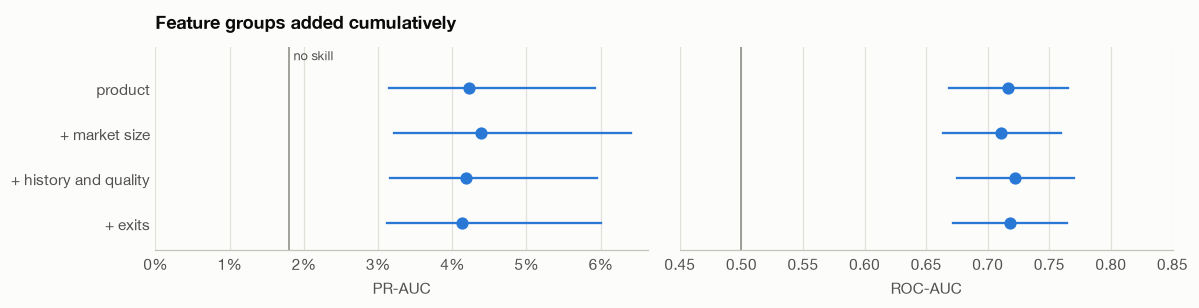

,PR-AUC,ROC-AUC,PR-AUC change from previous step (95% interval)
features,,,
product,0.042,0.72,—
+ market size,0.044,0.71,+0.002 (-0.009 to +0.015)
+ history and quality,0.042,0.72,-0.002 (-0.011 to +0.005)
+ exits,0.041,0.72,-0.001 (-0.005 to +0.004)


In [13]:
#| label: fig-ablation
#| fig-cap: "Logistic regression PR-AUC and ROC-AUC as feature groups are added, pooled 2021-2023"
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(11, 2.9), sharey=True)
dot_plot(ax_pr, ablation_table, "PR-AUC", "low", "high", [BLUE] * len(ablation_table),
         reference=BASE_RATE, reference_label="no skill")
ax_pr.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_pr.set_xlim(0, None)
ax_pr.set_xlabel("PR-AUC")
ax_pr.set_title("Feature groups added cumulatively")
dot_plot(ax_roc, ablation_table, "ROC-AUC", "ROC low", "ROC high", [BLUE] * len(ablation_table),
         reference=0.5)
ax_roc.set_xlim(0.45, 0.85)
ax_roc.set_xlabel("ROC-AUC")
fig.tight_layout()
plt.show()

ablation_table.assign(
    **{"PR-AUC": ablation_table["PR-AUC"].round(3), "ROC-AUC": ablation_table["ROC-AUC"].round(2)}
)[["PR-AUC", "ROC-AUC", "PR-AUC change from previous step (95% interval)"]].rename_axis(
    "features")

**What we learned.** Product features alone (route, drug age and the pre-1982 flag) score a PR-AUC
of 0.042 and a ROC-AUC of 0.72, as good as the full model. Adding market size, then history and
quality, then exits changes PR-AUC by at most 0.002 at each step, and every interval spans 0.

- **For prediction**, a three-feature model does the whole job. By the rule of preferring the
  simpler model when performance is equal, it is the better headline predictor; the full model is
  kept below because its coefficients answer RQ2.
- **For RQ3**, this is a negative predictive result: exits as recorded in NSDE, measured over the
  year before, add nothing to a ranking that already knows a drug's route and age. It is not yet
  an answer to RQ3. NSDE exit dates are largely administrative and lag by up to a year, which
  could blur a real signal. An effect confined to a few drugs wouldn't move pooled metrics. And the
  planned event study compares each drug with matched comparison drugs instead of ranking all
  drugs. The result suggests where to look: small markets of one to three packages, where a
  single exit removes much of the supply.

### What the logistic regression learned

Coefficients from the full logistic regression fit on 2020–2023, with the regularization chosen
for the 2023 test fold. Each is converted to an odds ratio in natural units: per doubling for
counts, per 10 years of age, per 10 percentage points of exit share, and yes vs no for flags and
routes (vs oral). Intervals come from refitting on 300 resamples of whole drugs. L2
regularization shrinks every coefficient toward 1, so these understate effect sizes somewhat,
and they describe association, adjusted for the other features, not cause.

In [14]:
FEATURE_LABELS = {
    "active_packages": "packages on the market (per doubling)",
    "active_applications": "active approvals (per doubling)",
    "cumulative_applicants": "companies ever approved (per doubling)",
    "recalls_prior_year": "recalls, prior year (per doubling)",
    "package_exits_prior_year": "package exits, prior year (per doubling)",
    "application_exits_prior_year": "approval exits, prior year (per doubling)",
    "discontinuation_notices_prior_year": "discontinuation notices (per doubling)",
    "years_since_first_approval": "years since first approval (per 10 years)",
    "package_exit_share": "share of packages exiting (per 10 points)",
    "approved_before_1982": "approved before 1982",
    "had_prior_shortage": "had a prior shortage",
    "route_injectable": "injectable (vs oral)",
    "route_ophthalmic": "ophthalmic (vs oral)",
    "route_topical": "topical (vs oral)",
    "route_other": "other routes (vs oral)",
}
NATURAL_UNITS = {
    **{column: np.log(2) for column in LOG_COUNTS},  # log1p(x) rises by about ln 2 per doubling
    "years_since_first_approval": 10,
    "package_exit_share": 0.1,
}
interpretation_rows = data[data["year"] <= 2023]
interpretation_C = chosen_params["logistic regression"][2023]["C"]


def odds_ratios(rows):
    model = logistic_regression(ALL_FEATURES, C=interpretation_C).fit(rows[ALL_FEATURES],
                                                                      rows["onset"])
    transform, regression = model[0], model[-1]
    names = [name.split("__", 1)[1] for name in transform.get_feature_names_out()]
    scale = pd.Series(1.0, index=names)
    scale[LOG_COUNTS] = transform.named_transformers_["log_counts"][-1].scale_
    scale[SCALED] = transform.named_transformers_["scaled"].scale_
    units_per_effect = pd.Series({name: NATURAL_UNITS.get(name, 1.0) for name in names})
    return np.exp(pd.Series(regression.coef_[0], index=names) / scale * units_per_effect)


fitted_odds = odds_ratios(interpretation_rows)
interpretation_rows_by_drug = list(interpretation_rows.groupby("unit_id").indices.values())
odds_draws = pd.DataFrame([
    odds_ratios(interpretation_rows.iloc[rows])
    for rows in drug_resamples(interpretation_rows_by_drug, resamples=300)
])
coefficients = pd.DataFrame(
    {
        "odds ratio": fitted_odds,
        "low": odds_draws.quantile(0.025),
        "high": odds_draws.quantile(0.975),
    }
).sort_values("odds ratio", ascending=False)
coefficients.index = coefficients.index.map(FEATURE_LABELS)

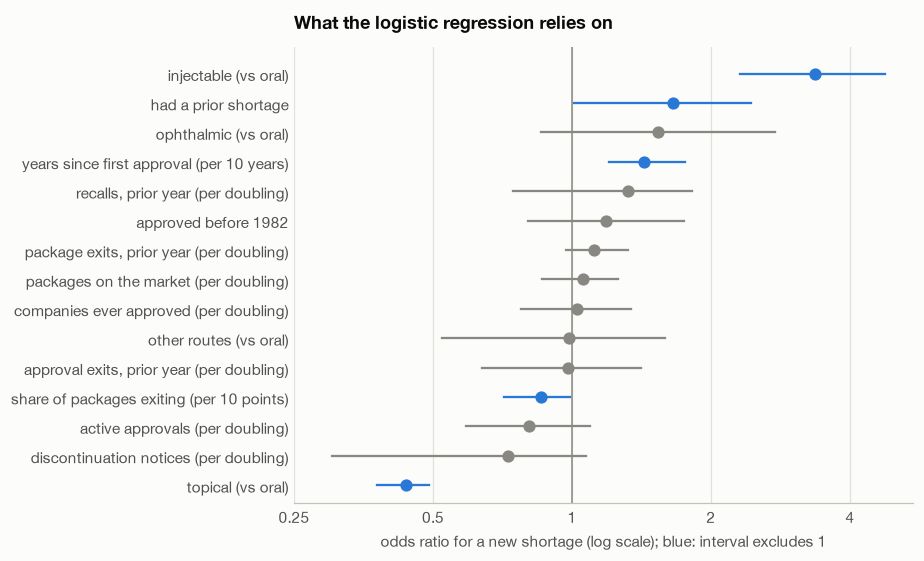

,odds ratio,low,high
feature,,,
injectable (vs oral),3.35,2.31,4.77
had a prior shortage,1.65,1.01,2.44
ophthalmic (vs oral),1.54,0.86,2.76
years since first approval (per 10 years),1.43,1.20,1.75
"recalls, prior year (per doubling)",1.32,0.74,1.82
approved before 1982,1.19,0.80,1.75
"package exits, prior year (per doubling)",1.12,0.97,1.32
packages on the market (per doubling),1.05,0.86,1.26
companies ever approved (per doubling),1.02,0.77,1.34


In [15]:
#| label: fig-coefficients
#| fig-cap: "Logistic regression odds ratios (2020-2023 fit) with 95% intervals resampling drugs"
fig, ax = plt.subplots(figsize=(8.5, 5.2))
clear = (coefficients["low"] > 1) | (coefficients["high"] < 1)
dot_plot(ax, coefficients, "odds ratio", "low", "high",
         [BLUE if is_clear else MUTED for is_clear in clear], reference=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
ax.minorticks_off()
ax.set_xlabel("odds ratio for a new shortage (log scale); blue: interval excludes 1")
ax.set_title("What the logistic regression relies on")
fig.tight_layout()
plt.show()

coefficients.round(2).rename_axis("feature")

**What we learned (RQ2).** Holding the other features fixed:

- **Route is the strongest factor.** Injectables have about 3.4 times the odds of oral drugs
  (2.3 to 4.8). Topical drugs are far lower, but their estimate rests on a single onset; its
  narrow interval reflects regularization pinning the coefficient, not precision.
- **Older drugs are riskier.** Each 10 years since first approval raises the odds by about 43%
  (1.20 to 1.75). The pre-1982 flag adds a little more on top, not clearly. Together: the oldest,
  most thoroughly generic drugs carry the most risk.
- **A prior shortage** raises the odds by about 65%, with an interval just above 1 (1.01 to
  2.44). The effect is real but modest, and the flag covers few drugs so far.
- **Market size and number of manufacturers show no clear effect** once route and age are known.
  Active approvals even lean protective (0.81, interval 0.59 to 1.09), matching the Exploration
  finding that single-manufacturer drugs don't go short more often. The low-margin, few-supplier
  account of shortages isn't contradicted by this. US approval counts don't see the overseas
  ingredient plants where supply is often concentrated.
- **Exits:** package exits lean positive (1.12, 0.97 to 1.32) and the share of packages exiting
  leans negative (0.86, 0.71 to 0.99). The two features are built from the same counts and
  largely offset each other, so together they don't show that losing packages raises risk.

These are associations, adjusted only for the features in the model. Route and age are markers
for a kind of market (old, low-margin sterile manufacturing), not causes.

## 7. Are the probabilities believable?

The reliability plot groups test drug-years into eight equal-sized bins by predicted risk and
compares the average prediction in each bin with the share that actually went short. Points on the
diagonal mean a predicted 4% risk really is 4%. The 2024–2025 predictions, from models rolled
forward the same way, are shown alongside. The Brier skill score compares each model's squared
error with always predicting the training years' base rate: above 0 is better than that, 0 is no
better.

In [16]:
late = {
    name: rolling_predictions(MODELS[name], test_years=LATE_YEARS)[0]
    for name in ["route rate (baseline)", "logistic regression", "gradient boosting"]
}
# Every model's predictions come back in the same row order, one year after another.
late_scores = late["logistic regression"][["unit_id", "year", "onset", "route"]].assign(
    **{name: predicted["score"].to_numpy() for name, predicted in late.items()}
)


def reliability(frame, column, bins=8):
    binned = frame.assign(bin=pd.qcut(frame[column].rank(method="first"), bins, labels=False))
    table = binned.groupby("bin").agg(predicted=(column, "mean"), onsets=("onset", "sum"),
                                      drug_years=("onset", "size"))
    table["observed"] = table["onsets"] / table["drug_years"]
    table["low"], table["high"] = wilson_interval(table["onsets"], table["drug_years"])
    return table


def brier_skill(frame, column):
    climatology = np.array([
        data.loc[data["year"] < year, "onset"].mean() for year in frame["year"]
    ])
    return 1 - brier_score_loss(frame["onset"], frame[column]) / brier_score_loss(
        frame["onset"], climatology)

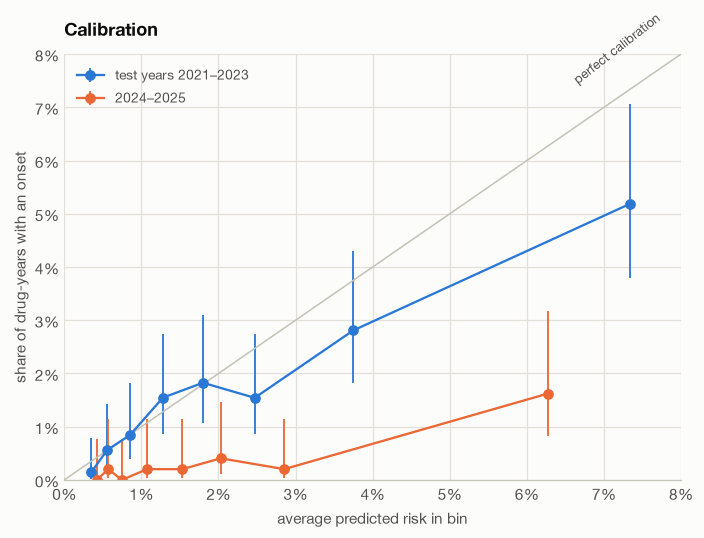

In [17]:
#| label: fig-calibration
#| fig-cap: "Predicted vs observed onset rate by bin of predicted risk, logistic regression"
fig, ax = plt.subplots(figsize=(6.5, 5))
for frame, label, color in [(scores, "test years 2021–2023", BLUE),
                            (late_scores, "2024–2025", ORANGE)]:
    table = reliability(frame, "logistic regression")
    ax.errorbar(table["predicted"], table["observed"],
                yerr=[table["observed"] - table["low"], table["high"] - table["observed"]],
                fmt="o-", color=color, ecolor=color, elinewidth=1.2, markersize=6, capsize=0,
                linewidth=1.5, label=label)
limit = 0.08
ax.plot([0, limit], [0, limit], color=BASELINE, linewidth=1)
ax.text(limit * 0.97, limit * 0.93, "perfect calibration", color=TEXT_SECONDARY, fontsize=8.5,
        ha="right", rotation=38)
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x")
ax.set_xlabel("average predicted risk in bin")
ax.set_ylabel("share of drug-years with an onset")
ax.set_title("Calibration")
ax.legend(loc="upper left", fontsize=9, labelcolor=TEXT_SECONDARY)
fig.tight_layout()
plt.show()

In [18]:
calibration_rows = []
for frame, period in [(scores, "2021–2023")] + [
    (late_scores[late_scores["year"] == year], str(year)) for year in LATE_YEARS
]:
    for name in ["route rate (baseline)", "logistic regression", "gradient boosting"]:
        calibration_rows.append({
            "period": period,
            "model": name,
            "onsets": int(frame["onset"].sum()),
            "observed rate": f"{frame['onset'].mean():.2%}",
            "mean predicted risk": f"{frame[name].mean():.2%}",
            "Brier skill score": round(brier_skill(frame, name), 4),
            "PR-AUC": round(average_precision_score(frame["onset"], frame[name]), 3),
            "ROC-AUC": round(roc_auc_score(frame["onset"], frame[name]), 2),
        })
pd.DataFrame(calibration_rows).set_index(["period", "model"])

onsets observed rate mean predicted risk  \
period    model                                                             
2021–2023 route rate (baseline)     103         1.81%               2.16%   
          logistic regression       103         1.81%               2.30%   
          gradient boosting         103         1.81%               2.17%   
2024      route rate (baseline)      11         0.56%               1.95%   
          logistic regression        11         0.56%               2.10%   
          gradient boosting          11         0.56%               2.05%   
2025      route rate (baseline)       3         0.15%               1.67%   
          logistic regression         3         0.15%               1.78%   
          gradient boosting           3         0.15%               1.45%   

                                 Brier skill score  PR-AUC  ROC-AUC  
period    model                                                      
2021–2023 route rate (baseline)             0.0075   0.031     0.66  
          logistic regression               0.0065   0.041     0.72  
          gradient boosting                -0.0295   0.032     0.68  
2024      route rate (baseline)            -0.0120   0.011     0.71  
          logistic regression              -0.0142   0.072     0.82  
          gradient boosting                -0.0053   0.049     0.82  
2025      route rate (baseline)            -0.0844   0.002     0.54  
          logistic regression              -0.1459   0.007     0.66  
          gradient boosting                -0.0615   0.013     0.66

**What we learned.**

- **In 2021–2023 the probabilities are roughly right, but slightly too high**, especially at the
  top: the riskiest eighth of drug-years averaged 7.3% predicted and 5.2% observed, and the
  overall mean is 2.3% predicted against 1.8% observed. The training years include 2020, when the
  onset rate was higher (2.4%). The Brier skill score is barely above 0 (0.007): with a signal this
  weak, the probabilities hardly beat always predicting the base rate, so the model's value is
  in the ranking. Gradient boosting's probabilities are worse than the base rate (negative skill).
- **After 2023 the ranking holds but the probabilities don't.** In 2024, logistic regression's
  ROC-AUC is 0.82 and its PR-AUC is 13 times the base rate, although with 11 onsets that is very
  uncertain. But every model predicts about 2% risk when the actual rate fell to 0.56% in 2024
  and 0.15% in 2025, 4 to 12 times too high. Three onsets in 2025 are too few to read anything
  into its ranking.
- **Implication.** Nothing at the drug level predicts the post-2023 collapse in new shortages,
  so probabilities should be presented as relative risk, or have their overall level reset each
  year to a current base rate (for example, FDA's count of new shortages the year before).

## 8. Injectable vs oral drugs (RQ4)

First, the pooled test predictions from section 5, scored separately within each group: does the
model rank injectables well against other injectables, and oral drugs against other oral drugs?
Route itself can't help within a group, so this isolates everything else the model knows.

In [19]:
subgroup_rows = []
for group in ["injectable", "oral"]:
    group_scores = scores[scores["route"] == group].reset_index(drop=True)
    group_resamples = drug_resamples(list(group_scores.groupby("unit_id").indices.values()))
    group_roc_draws = bootstrap_metrics(group_scores, CANDIDATES, roc_auc_score, group_resamples)
    group_pr_draws = bootstrap_metrics(group_scores, CANDIDATES, average_precision_score,
                                       group_resamples)
    for position, name in enumerate(CANDIDATES):
        roc = roc_auc_score(group_scores["onset"], group_scores[name])
        pr = average_precision_score(group_scores["onset"], group_scores[name])
        subgroup_rows.append({
            "group": group,
            "model": name,
            "drug-years": len(group_scores),
            "onsets": int(group_scores["onset"].sum()),
            "base rate": f"{group_scores['onset'].mean():.2%}",
            "PR-AUC (95% interval)": f"{pr:.3f} ({np.percentile(group_pr_draws[:, position], 2.5):.3f}"
            f"–{np.percentile(group_pr_draws[:, position], 97.5):.3f})",
            "× base rate": round(pr / group_scores["onset"].mean(), 1),
            "ROC-AUC (95% interval)": f"{roc:.2f} ({np.percentile(group_roc_draws[:, position], 2.5):.2f}"
            f"–{np.percentile(group_roc_draws[:, position], 97.5):.2f})",
        })
pd.DataFrame(subgroup_rows).set_index(["group", "model"])

drug-years  onsets base rate  \
group      model                                               
injectable logistic regression        1497      62     4.14%   
           random forest              1497      62     4.14%   
           gradient boosting          1497      62     4.14%   
oral       logistic regression        3096      31     1.00%   
           random forest              3096      31     1.00%   
           gradient boosting          3096      31     1.00%   

                               PR-AUC (95% interval)  × base rate  \
group      model                                                    
injectable logistic regression   0.056 (0.040–0.087)          1.4   
           random forest         0.050 (0.036–0.074)          1.2   
           gradient boosting     0.046 (0.035–0.065)          1.1   
oral       logistic regression   0.016 (0.011–0.029)          1.6   
           random forest         0.014 (0.009–0.025)          1.4   
           gradient boosting     0.017 (0.010–0.039)          1.7   

                               ROC-AUC (95% interval)  
group      model                                       
injectable logistic regression       0.61 (0.54–0.68)  
           random forest             0.57 (0.51–0.64)  
           gradient boosting         0.55 (0.48–0.62)  
oral       logistic regression       0.66 (0.57–0.74)  
           random forest             0.62 (0.52–0.72)  
           gradient boosting         0.63 (0.53–0.73)

Second, transfer: logistic regression trained on one group only (without route, which is constant
within a group) and tested on each group, with the same rolling years and nested tuning. If the
two groups' shortages follow the same pattern, a model trained on injectables should rank oral
drugs about as well as one trained on oral drugs.

In [20]:
GROUPS = ["injectable", "oral"]
no_route = [column for column in ALL_FEATURES if column != "route"]
transfer_rows = []
for train_group in GROUPS:
    for test_group in GROUPS:
        transferred, _ = rolling_predictions(
            MODELS["logistic regression"],
            no_route,
            train_rows=(data["route"] == train_group).to_numpy(),
            test_rows=(data["route"] == test_group).to_numpy(),
        )
        transfer_rows.append({
            "trained on": train_group,
            "tested on": test_group,
            "PR-AUC": average_precision_score(transferred["onset"], transferred["score"]),
            "× base rate": average_precision_score(transferred["onset"], transferred["score"])
            / transferred["onset"].mean(),
            "ROC-AUC": roc_auc_score(transferred["onset"], transferred["score"]),
        })
pd.DataFrame(transfer_rows).set_index(["trained on", "tested on"]).round(
    {"PR-AUC": 3, "× base rate": 1, "ROC-AUC": 2})

PR-AUC  × base rate  ROC-AUC
trained on tested on                               
injectable injectable   0.051          1.2     0.60
           oral         0.013          1.3     0.59
oral       injectable   0.067          1.6     0.63
           oral         0.019          1.9     0.66

**What we learned (RQ4).**

- **Within each group, ranking is weaker than overall.** Logistic regression's ROC-AUC is 0.61
  among injectables (0.54 to 0.68) and 0.66 among oral drugs (0.57 to 0.74), against 0.72 for all
  drugs together, and PR-AUC is only 1.4 to 1.6 times each group's base rate. Much of the overall
  skill comes from telling injectables from oral drugs. Among injectables, where most onsets
  happen, the model is only modestly better than chance.
- **Predictability is similarly modest in both groups.** Their intervals overlap widely, so there
  is no sign the model works for one group and not the other. The tree models do no better within
  either group, so a missed route-by-feature interaction doesn't explain the weak within-group
  ranking.
- **Transfer works about as well as training within a group.** A model trained only on oral drugs
  ranks injectables at least as well (0.63) as one trained on injectables (0.60), and the
  injectable-trained model ranks oral drugs nearly as well as the oral-trained one (0.59 vs 0.66).
  The same pattern, older drugs being riskier, seems to operate in both. With 31 oral test
  onsets, only a large difference between the groups could have been detected.

## 9. Errors: what the model gets wrong

### Where the onsets landed in each year's ranking

If the model had no skill, onsets would be spread evenly across the ranking. The histogram shows
where each of the 103 test onsets fell in its year's logistic-regression ranking.

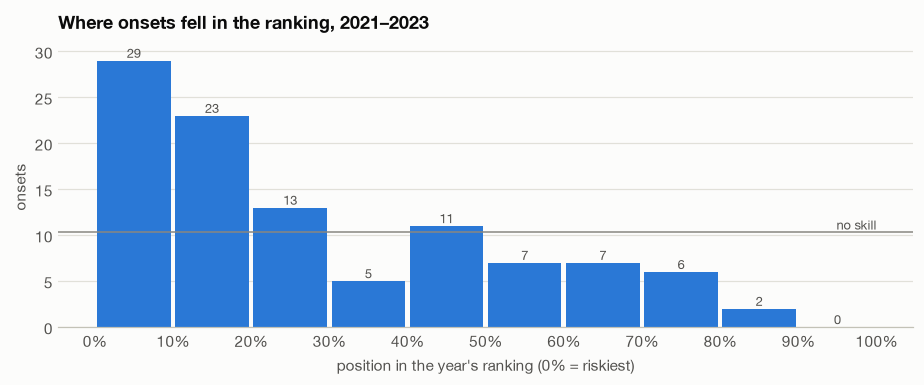

In [21]:
#| label: fig-onset-ranks
#| fig-cap: "Position of each test-year onset in that year's logistic regression ranking"
ranked = scores.assign(
    rank_share=scores.groupby("year")["logistic regression"].rank(ascending=False, pct=True,
                                                                  method="first"),
    rank=scores.groupby("year")["logistic regression"].rank(ascending=False, method="first"),
)
onset_ranks = ranked[ranked["onset"] == 1]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
edges = np.linspace(0, 1, 11)
counts, _ = np.histogram(onset_ranks["rank_share"], edges)
ax.bar(edges[:-1] + 0.05, counts, width=0.094, color=BLUE)
ax.axhline(len(onset_ranks) / 10, color=MUTED, linewidth=1)
ax.text(1, len(onset_ranks) / 10, "no skill", color=TEXT_SECONDARY, fontsize=8.5, ha="right",
        va="bottom")
for x, count in zip(edges[:-1] + 0.05, counts):
    ax.text(x, count, f"{count}", ha="center", va="bottom", fontsize=8.5, color=TEXT_SECONDARY)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xticks(edges)
ax.set_xlabel("position in the year's ranking (0% = riskiest)")
ax.set_ylabel("onsets")
ax.set_title("Where onsets fell in the ranking, 2021–2023")
fig.tight_layout()
plt.show()

### False alarms: high-ranked drugs that did not go short

Drugs that made a year's top 50 without an onset, most frequent first. The last column checks
whether they went short in a *later* year of the panel (through 2025), which would make them
early rather than wrong.

In [22]:
on_watchlist = ranked["rank"] <= WATCHLIST_SIZE
false_alarms = ranked[on_watchlist & (ranked["onset"] == 0)].merge(
    data[["unit_id", "year", "ingredient", "years_since_first_approval", "approved_before_1982",
          "active_packages", "active_applications", "had_prior_shortage"]],
    on=["unit_id", "year"],
)
all_onset_years = panel.loc[panel["onset"] == 1].groupby("unit_id")["year"].apply(set)


def went_short_later(unit_id, year):
    return any(onset_year > year for onset_year in all_onset_years.get(unit_id, set()))


false_alarms["went short later"] = [
    went_short_later(unit_id, year)
    for unit_id, year in zip(false_alarms["unit_id"], false_alarms["year"])
]
other_non_onsets = ranked[~on_watchlist & (ranked["onset"] == 0)]
later_rate_watchlist = false_alarms["went short later"].mean()
later_rate_others = np.mean([
    went_short_later(unit_id, year)
    for unit_id, year in zip(other_non_onsets["unit_id"], other_non_onsets["year"])
])
print(f"false alarms on the top-{WATCHLIST_SIZE} lists: {len(false_alarms)} drug-years, "
      f"{false_alarms['unit_id'].nunique()} drugs")
print(f"went short in a later panel year: {later_rate_watchlist:.1%} of false alarms vs "
      f"{later_rate_others:.1%} of other non-onset drug-years")
(
    false_alarms.groupby(["ingredient", "route"])
    .agg(
        years_on_list=("year", "size"),
        years_since_first_approval=("years_since_first_approval", "max"),
        approved_before_1982=("approved_before_1982", "max"),
        packages=("active_packages", "median"),
        approvals=("active_applications", "median"),
        prior_shortage=("had_prior_shortage", "max"),
        went_short_later=("went short later", "max"),
    )
    .sort_values(["years_on_list", "packages"], ascending=False)
    .head(12)
)

false alarms on the top-50 lists: 144 drug-years, 107 drugs
went short in a later panel year: 9.7% of false alarms vs 2.1% of other non-onset drug-years


,,years_on_list,years_since_first_approval,approved_before_1982,packages,approvals,prior_shortage,went_short_later
ingredient,route,,,,,,,
AMPICILLIN SODIUM,injectable,3,41.0,1,124.0,13.0,0,False
CYANOCOBALAMIN,injectable,3,41.0,1,62.0,9.0,0,False
TESTOSTERONE CYPIONATE,injectable,3,41.0,1,39.0,6.0,0,False
METOCLOPRAMIDE HYDROCHLORIDE,injectable,3,41.0,1,23.0,4.0,1,False
PHENYTOIN SODIUM,injectable,3,41.0,1,16.0,2.0,1,False
AMINOPHYLLINE,injectable,3,41.0,1,14.0,1.0,1,False
PYRIDOXINE HYDROCHLORIDE,injectable,3,41.0,1,3.0,1.0,0,False
GLYCOPYRROLATE,injectable,2,40.0,1,179.5,17.0,0,False
CLINDAMYCIN PHOSPHATE,injectable,2,40.0,1,86.0,10.0,0,True


### Missed onsets: shortages ranked in the bottom half

In [23]:
missed = onset_ranks[onset_ranks["rank_share"] > 0.5].merge(
    data[["unit_id", "year", "ingredient", "years_since_first_approval", "approved_before_1982",
          "active_packages", "active_applications", "had_prior_shortage", "recalls_prior_year"]],
    on=["unit_id", "year"],
)
caught = onset_ranks[onset_ranks["rank_share"] <= 0.5].merge(
    data[["unit_id", "year", "years_since_first_approval", "approved_before_1982",
          "active_packages"]],
    on=["unit_id", "year"],
)
print(f"onsets ranked in the bottom half of their year: {len(missed)} of {len(onset_ranks)}")
print("route of missed onsets:", missed["route"].value_counts().to_dict())
print(f"median years since first approval: missed {missed['years_since_first_approval'].median():.0f}, "
      f"ranked in top half {caught['years_since_first_approval'].median():.0f}")
print(f"approved before 1982: missed {missed['approved_before_1982'].mean():.0%}, "
      f"ranked in top half {caught['approved_before_1982'].mean():.0%}")
missed.sort_values("rank_share", ascending=False)[
    ["year", "ingredient", "route", "rank_share", "years_since_first_approval", "active_packages",
     "active_applications", "had_prior_shortage"]
].head(12).assign(rank_share=lambda table: table["rank_share"].map("{:.0%}".format)).rename(
    columns={"rank_share": "position in ranking"}).reset_index(drop=True)

onsets ranked in the bottom half of their year: 22 of 103
route of missed onsets: {'oral': 9, 'injectable': 8, 'other': 3, 'ophthalmic': 2}
median years since first approval: missed 11, ranked in top half 39
approved before 1982: missed 5%, ranked in top half 63%


,year,ingredient,route,position in ranking,years_since_first_approval,active_packages,active_applications,had_prior_shortage
0,2021,AMPHETAMINE; AMPHETAMINE ASPARTATE/DEXTROAMPHETAMINE SULFATE,oral,83%,5.2,1,1,0
1,2022,"BAZEDOXIFENE ACETATE; ESTROGENS, CONJUGATED",oral,81%,8.2,2,1,0
2,2021,VARENICLINE TARTRATE,oral,79%,14.6,11,1,0
3,2022,DIAZEPAM,other,79%,24.4,6,1,0
4,2022,VANDETANIB,oral,78%,10.7,2,1,0
5,2023,RIVAROXABAN,oral,76%,11.5,31,2,0
6,2022,ALPROSTADIL,other,71%,25.1,12,1,0
7,2023,LISDEXAMFETAMINE DIMESYLATE,oral,70%,15.9,13,2,0
8,2021,TRIMETHOBENZAMIDE HYDROCHLORIDE,oral,68%,19.0,16,3,0
9,2021,DESMOPRESSIN ACETATE,other,67%,39.0,10,6,0


**What we learned.**

- **The ranking is front-loaded but leaky.** Half the onsets (52 of 103) fall in the riskiest 20%
  of their year's ranking, 2.5 times what chance would give, but 22 fall in the bottom half.
- **False alarms are the textbook shortage profile.** The top of every year's list is old
  (pre-1982) sterile injectables, many with dozens of packages and several manufacturers:
  ampicillin, cyanocobalamin, phenytoin, aminophylline. Some are early rather than wrong: 9.7% of
  false-alarm drug-years went short in a later panel year, against 2.1% of other drug-years
  without an onset. But most old injectables don't go short in a given year, and nothing in these
  features separates the few that will. That sets the ceiling on precision.
- **Missed onsets are a different kind of shortage.** They are newer drugs (median 11 years since
  first approval, against 39 for onsets ranked in the top half; 5% pre-1982 against 63%), usually
  often with a single approval, and often brand-name oral drugs. Examples are lisdexamfetamine in
  2023, during the ADHD stimulant shortage driven by demand and controlled-substance production
  limits, and varenicline, whose 2021 shortage followed impurity recalls in the same year, too
  late for a feature measured at the end of 2020. Demand surges,
  quotas and sudden quality failures aren't in these supply-side features.

In short, the model finds the chronic shortage risk of old generic injectables and misses acute
shocks to newer drugs. Demand-side data (the deferred Medicare features) is the obvious
candidate for the second kind.

## Summary of modeling choices

| Decision | Choice | Why |
|---|---|---|
| Task | Rank at-risk drugs by risk of a new shortage next year (binary classification used as a ranking) | A watchlist is the usable output; at a 1.8% base rate, yes/no predictions are uninformative |
| Validation | Rolling origin: test years 2021, 2022, 2023, pooled; tuning by rolling validation inside the training years; 2024–2025 as a separate check | Never trains on the future; 103 pooled test onsets instead of about 35 |
| Metrics | PR-AUC against the base rate (primary), ROC-AUC, onsets in a 50-drug watchlist, calibration | Rare positives, ranking use, and the promise of probabilities |
| Baselines | Prior-shortage flag; route-group rate | The flag was promised; route is the largest single difference |
| Selected model | L2 logistic regression, `C` = 0.3 | Ties or beats the tree models, better calibrated, simplest, interpretable |
| Features | Route, age and the pre-1982 flag carry all of the predictive signal; full set kept for interpretation | Equal performance favors the simpler model; the coefficients answer RQ2 |
| Not adopted | Random forest, gradient boosting, class weights, a calendar-year feature | No gain; class weights would distort probabilities; year can only extrapolate |

**Answers so far.** RQ1: onsets are modestly predictable a year ahead (ROC-AUC 0.72, PR-AUC 2.3
times the base rate), mostly from route and drug age. RQ2: injectables and older drugs are
riskier, a prior shortage adds some risk, and market size and manufacturer counts add nothing
once those are known. RQ3: year-level exits from NSDE add no predictive value; the event study
is still needed. RQ4: within-group predictability is modest for both injectable and oral drugs,
and a model trained on one group transfers to the other.

**Next steps.** The RQ3 event study, focusing on small markets; resetting the probabilities'
overall level to a current base rate; and, if they can be linked, demand features for the acute
shortages the model misses.

## What this evaluation does not show

- **Not causal.** Coefficients are associations adjusted only for the other features. Route and
  age stand in for a kind of market; they aren't mechanisms.
- **Not proof that exits don't matter.** Only that year-level NSDE exits don't improve a ranking
  of all drugs.
- **Small samples.** With 103 test onsets, PR-AUC differences of about 0.01 between models are
  within noise, and the order of the candidates could change with more years.
- **The label is FDA's listing of a lasting shortage**, from late 2019 on. Short shortages are
  missing, and a model trained on these labels learns to predict listings, not supply failures.
- **No robustness to a regime change.** The collapse in new shortages after 2023 broke the
  probabilities; the ranking held in 2024, and 2025 can't be judged.
- **Scope.** Approved, non-biologic prescription drugs, with drugs defined by Orange Book
  ingredient text. The prior-shortage feature will mean more as the archive's history grows,
  so its estimated effect may change.